# Training walkthrough

Train the two diffusion models of CRG-DefectDiffuser on your preprocessed PKU images, one after the other, then benchmark them against the authors' checkpoints.

| Part | What it does |
|---|---|
| Steps 1–4 | Walk through the data, the model, the forward process and one training step (uses `MODEL`) |
| Step 5 | Train the **64 defect model**, then the **256 defect-free model**, with `torch.compile` |
| Step 6 | Loss curves of both runs |
| Step 7 | Pick each model's best checkpoint on held-out photos |
| Step 8 | Benchmark: ours vs the authors' checkpoints (KID, FID, precision/recall, memorisation) |

**Training images** (made by `preprocess_walkthrough.ipynb`, from boards 01 and 04–09):

| Folder | Contents | Trains |
|---|---|---|
| `data/pcb_processed/defect_64/` | 64×64 patches around each defect, named `short_0001.jpg` … | 64 class-conditional defect model |
| `data/pcb_processed/free_256/` | 256×256 crops with the defects removed, named `free_00001.jpg` … | 256 defect-free model |

**What training does.** Take a clean image $x_0$, pick a random timestep $t$, add noise to get $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$, and teach the UNet to predict that noise $\varepsilon$ from $x_t$ and $t$ (plus the class for the 64 model).

Run in the `crg-defect` kernel. *Run All* takes about 36 hours when continuing from 50k steps on the RTX 4090; checkpoints are saved along the way, so an interrupted run resumes.

In [1]:
%matplotlib inline
import copy
import gc
import json
import math
import random
import shutil
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from omegaconf import OmegaConf
from PIL import Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "third_party" / "CRG-DefectDiffuser").is_dir())
REPO = ROOT / "third_party" / "CRG-DefectDiffuser"
sys.path.insert(0, str(REPO))

from guided_diffusion import unet as U
from guided_diffusion.gaussian_diffusion import get_named_beta_schedule
from guided_diffusion.image_datasets import load_data
from guided_diffusion.nn import update_ema
from guided_diffusion.resample import UniformSampler
from guided_diffusion.script_util import (create_gaussian_diffusion, create_model,
                                          diffusion_defaults, model_defaults, select_args)

device = "cuda"
CLASSES = json.load(open(REPO / "data" / "pcb.json"))          # missinghole -> 0, ...
ID2NAME = {v: k for k, v in CLASSES.items()}
print("ROOT", ROOT, "|", torch.cuda.get_device_name(0))

ROOT /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design | NVIDIA GeForce RTX 4090


## Settings

| Setting | Value | Source |
|---|---|---|
| Defect patches | **50 per class**, 64×64 | DEFectDiffuser paper, Sec. IV-A |
| Defect-free crops | **about 3,000**, 256×256 | DEFectDiffuser paper, Sec. IV-A |
| Optimizer, lr, weight decay | AdamW, 1e-4, 0 | authors' repo, `confs/train-*.yml` |
| Batch size | 64 (64 model), 8 (256 model) | authors' repo |
| EMA, mixed precision | 0.9999, fp16 | authors' repo |
| Diffusion | 1000 steps, linear β, ε-prediction + learned variance | authors' repo |
| **Training steps** | 200k (64 model), 500k (256 model) | the authors journal paper (CRG, TCSVT 2026, Sec. IV-A): DPM 200,000 and CSM 500,000 iterations; the best checkpoint is still picked in Step 7 |

`FAST = True` trains through `torch.compile`. The maths is unchanged (gradients equal up to fp16 rounding); it is about 1.7× faster for the 64 model.

In [2]:
MODEL = "64"                 # 步骤 1–4 演示用哪个模型："64" 缺陷模型 \ "256" 无缺陷背景模型
LOG_EVERY = 500
RESUME = True                # RUN_DIR 里已有 checkpoint 时接着训练
USE_AMP = True               # 混合精度（与仓库 use_fp16: true 相同）
FAST = True                  # torch.compile 加速：数学不变，首步需 1–2 分钟编译
SEED = 0

# 数据规模取自 DEFectDiffuser 论文 Sec. IV-A；batch / lr / EMA 取自作者仓库的 confs/train-*.yml；
# 训练步数取自 CRG 论文（TCSVT 2026）Sec. IV-A：DPM 200,000 次，CSM 500,000 次
RUNS = {
    "64":  dict(cfg="train-64.yml",  data="defect_64", per_class=50,   max_steps=200000, save_every=10000, preview_every=20000),
    "256": dict(cfg="train-256.yml", data="free_256",  per_class=None, max_steps=500000, save_every=25000, preview_every=50000),
}

# 评估设置（步骤 7、8）
EVAL_STEPS = 50                      # DDIM 步数，所有模型相同
N_SELECT = {"64": 600, "256": 300}   # 选 checkpoint 时生成的样本数（64 模型每类均分）
N_TEST = {"64": 600, "256": 600}     # 最终比较时生成的样本数
RESULTS = ROOT / "results" / "comparison"


def run_dir(kind):
    r = RUNS[kind]
    name = ("defect_64" if kind == "64" else "free_256") + (f"_{r['per_class']}pc" if r["per_class"] else "")
    return ROOT / "runs" / name


def load_cfg(kind):
    return yaml.safe_load(open(REPO / "confs" / RUNS[kind]["cfg"]))


cfg = load_cfg(MODEL)
BATCH = cfg["batch_size"]      # 64 或 8
LR = float(cfg["lr"])
EMA_RATE = float(cfg["ema_rate"])
for k in RUNS:
    c = load_cfg(k)
    print(f"MODEL {k} \n batch {c['batch_size']} \n lr {c['lr']} \n EMA {c['ema_rate']} \n "
          f"steps {RUNS[k]['max_steps']} \n run dir {run_dir(k)}")

MODEL 64 
 batch 64 
 lr 1e-4 
 EMA 0.9999 
 steps 200000 
 run dir /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design/runs/defect_64_50pc
MODEL 256 
 batch 8 
 lr 1e-4 
 EMA 0.9999 
 steps 500000 
 run dir /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design/runs/free_256


## Step 1 · The training images

Count the images and, for the 64 model, how many there are per class. The class comes from the text before the first `_` in each file name; `load_data` reads it the same way.

With `per_class` set, a fixed random subset of that many patches per class is copied to its own folder (`defect_64_50pc/`).

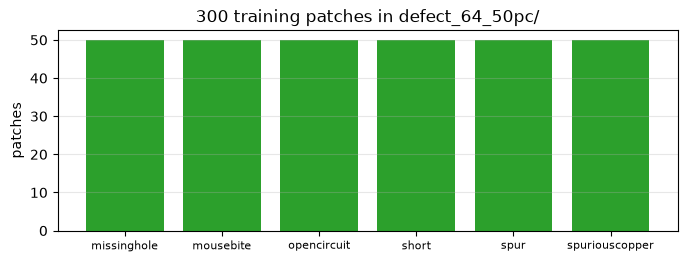

batch (64, 3, 64, 64) pixel range [-1.00, 1.00]


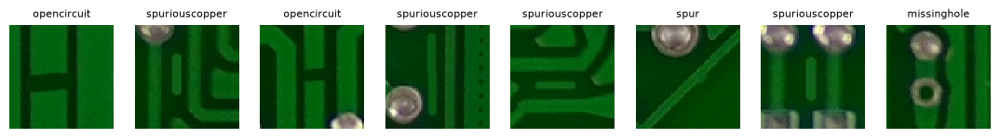

In [3]:
def data_dir(kind):
    """训练图像目录；per_class 不为空时建立每类 N 张的子集（固定随机种子）"""
    r = RUNS[kind]
    d = ROOT / "data" / "pcb_processed" / r["data"]
    files = sorted(d.glob("*.jpg"))
    assert files, f"No images in {d}. Run preprocess_walkthrough.ipynb step 7 (BUILD = True) first."
    if kind == "64" and r["per_class"]:
        sub = d.parent / f"{r['data']}_{r['per_class']}pc"
        if not sub.exists():
            rng = random.Random(SEED)
            sub.mkdir()
            for name in CLASSES:
                pick = sorted(f for f in files if f.name.split("_")[0] == name)
                for f in rng.sample(pick, min(r["per_class"], len(pick))):
                    shutil.copy(f, sub / f.name)
        d = sub
    return d


DATA_DIR = data_dir(MODEL)
files = sorted(DATA_DIR.glob("*.jpg"))
if MODEL == "64":
    count = Counter(f.name.split("_")[0] for f in files)
    fig, ax = plt.subplots(figsize=(8, 2.6))
    ax.bar(list(CLASSES), [count[n] for n in CLASSES], color="tab:green")
    ax.set_ylabel("patches"), ax.set_title(f"{len(files)} training patches in {DATA_DIR.name}/")
    ax.tick_params(axis="x", labelsize=8); ax.grid(axis="y", alpha=0.3)
    plt.show()
else:
    print(f"{len(files)} defect-free crops in {DATA_DIR.name}/")

assert len(files) >= BATCH, "load_data drops the last incomplete batch, so it needs at least BATCH images"

# 用仓库自己的 load_data，得到的就是训练时的批次
data = load_data(data_dir=DATA_DIR, batch_size=BATCH, image_size=int(MODEL),
                 class_dict=CLASSES if MODEL == "64" else None, shuffle=True)
x, y = next(data)
print("batch", tuple(x.shape), "pixel range", f"[{x.min():.2f}, {x.max():.2f}]")

n = 8
fig, axes = plt.subplots(1, n, figsize=(1.7 * n, 2.1))
for ax, im, lab in zip(axes, x[:n], y[:n]):
    ax.imshow(((im.permute(1, 2, 0) + 1) / 2).numpy(), interpolation="nearest"); ax.set_axis_off()
    ax.set_title(ID2NAME[int(lab)] if MODEL == "64" else "free", fontsize=8)
plt.show()

## Step 2 · Build the model and the diffusion process

Both come from the repo, configured by the same YAML the authors used. The architecture keys match `confs/pcb_gen.yml`, so a checkpoint trained here loads into `sample_generation.py` and `sample_checkpoints.ipynb` without changes.

In [4]:
def build(kind):
    """按训练配置建 UNet（fp32 权重；混合精度靠 autocast）"""
    c = load_cfg(kind)
    arch = select_args(c, model_defaults().keys())
    arch["use_fp16"] = False
    return create_model(**arch, num_classes=len(CLASSES) if kind == "64" else None).to(device)


torch.manual_seed(SEED)
model = build(MODEL)
diffusion = create_gaussian_diffusion(**select_args(cfg, diffusion_defaults().keys()), conf=OmegaConf.create(cfg))
sampler = UniformSampler(diffusion)                        # 每个 t 被抽到的概率相同

print(f"parameters {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")
print(f"diffusion steps {diffusion.num_timesteps} · output channels {model.out[-1].out_channels} "
      f"(3 for the noise ε, 3 for the learned variance)")

create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


parameters 25.1 M
diffusion steps 1000 · output channels 6 (3 for the noise ε, 3 for the learned variance)


## Step 3 · The forward process: what noise the model must undo

`diffusion.q_sample(x0, t)` adds exactly the amount of noise of timestep $t$ in one go. During training every image in a batch gets its own random $t$ between 0 and 999.

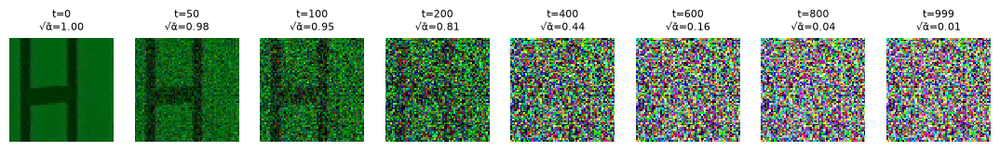

In [5]:
x0 = x[:1].to(device)
ts = [0, 50, 100, 200, 400, 600, 800, 999]
noise = torch.randn_like(x0)
fig, axes = plt.subplots(1, len(ts), figsize=(1.7 * len(ts), 2.1))
for ax, t in zip(axes, ts):
    xt = diffusion.q_sample(x0, torch.tensor([t], device=device), noise=noise)
    ax.imshow(((xt[0].permute(1, 2, 0).cpu() + 1) / 2).clamp(0, 1).numpy(), interpolation="nearest")
    ax.set_title(f"t={t}\n√ᾱ={diffusion.sqrt_alphas_cumprod[t]:.2f}", fontsize=8); ax.set_axis_off()
plt.show()

## Step 4 · One training step, by hand

`diffusion.training_losses` does all of this; it is written out here so you can see each piece:

1. sample one random $t$ per image
2. make $x_t$ from the clean image and fresh noise $\varepsilon$
3. the UNet predicts $\hat\varepsilon$ (first 3 channels) and a variance (last 3)
4. **mse** $= \lVert \varepsilon - \hat\varepsilon \rVert^2$, the main loss; **vb** trains the variance only
5. backpropagate `mse + vb` and take one optimizer step (done in Step 5)

Before any training the model outputs about zero, so mse starts near 1, the variance of the noise.

In [6]:
xb, yb = x.to(device), y.to(device)
kw = {"y": yb} if MODEL == "64" else {}
t, weights = sampler.sample(xb.shape[0], device)

with torch.no_grad():
    losses = diffusion.training_losses(model, xb, t, model_kwargs=kw)
print("timesteps of this batch:", t[:8].tolist(), "...")
print(f"mse {losses['mse'].mean():.4f} · vb {losses['vb'].mean():.4f} · loss {losses['loss'].mean():.4f}")

# 手动复现 mse，与上面的数值对照
noise = torch.randn_like(xb)
with torch.no_grad():
    xt = diffusion.q_sample(xb, t, noise=noise)
    eps_hat = model(xt, diffusion._scale_timesteps(t), **kw)[:, :3]
print(f"by hand: mse {((noise - eps_hat) ** 2).mean():.4f}")

timesteps of this batch: [582, 456, 426, 666, 961, 246, 409, 434] ...
mse 0.9989 · vb 0.0121 · loss 1.0110
by hand: mse 0.9984


## Step 5 · Train both models in sequence

`train(kind)` is the repo's `TrainLoop` written out: same optimizer, loss, timestep sampling, mixed precision and EMA. It writes to `runs/defect_64_50pc/` and `runs/free_256/`:

| File | Contents |
|---|---|
| `model{step}.pt` | current weights |
| `ema_0.9999_{step}.pt` | EMA weights, used for sampling and evaluation |
| `opt{step}.pt` | optimizer state, kept only for the latest step (for resuming) |
| `preview_{step}.png` | samples from both weight sets, same noise every time |
| `loss_history.json`, `train_log.txt` | loss and speed log |

**Speed.** With `FAST = True` the forward and backward pass run through `torch.compile(model)`, the attention blocks skip their memory-saving re-computation (same gradients, about 2 GB more memory) and tensors use the channels-last layout. Checkpoints, EMA and previews use the plain model, so the saved files are unchanged. Measured: about 760 img/s for the 64 model (vs 445 without), about 35 img/s for the 256 model.

**Time.** 64 model: about 7 h for 200k steps. 256 model: about 30 h for 500k steps. Both runs were first trained to 50k steps and continue from there; the 256 run continues on the repaired defect-free crops (preprocessing step 8). Stopping the cell is safe; rerun it with `RESUME = True` and each run continues from its last checkpoint (a finished run is skipped).

In [7]:
AB = torch.tensor(np.cumprod(1.0 - get_named_beta_schedule("linear", 1000, use_scale=True)),
                  dtype=torch.float32, device=device)


@torch.no_grad()
def ddim_sample(net, kind, y=None, n=None, steps=EVAL_STEPS, seed=SEED):
    """确定性 DDIM（σ=0），从纯噪声采样；返回 uint8 图像 (N,3,H,W)。同一 seed 得到同一份初始噪声"""
    s = int(kind)
    n = len(y) if y is not None else n
    bs = 200 if kind == "64" else 24
    g = torch.Generator(device=device).manual_seed(seed)
    ts = np.linspace(999, 0, steps).round().astype(int)
    was_training = net.training
    net.eval()
    out = []
    for i in range(0, n, bs):
        b = min(bs, n - i)
        xx = torch.randn((b, 3, s, s), device=device, generator=g)
        yy = y[i:i + b].to(device) if y is not None else None
        for k, t in enumerate(ts):
            with torch.autocast("cuda", dtype=torch.float16):
                eps = net(xx, torch.full((b,), int(t), device=device), yy)[:, :3].float()
            x0 = ((xx - (1 - AB[t]).sqrt() * eps) / AB[t].sqrt()).clamp(-1, 1)
            xx = x0 if k == len(ts) - 1 else AB[ts[k + 1]].sqrt() * x0 + (1 - AB[ts[k + 1]]).sqrt() * eps
        out.append(((xx + 1) * 127.5).round().clamp(0, 255).to(torch.uint8).cpu())
    net.train(was_training)
    return torch.cat(out)


def show_row(ax_row, imgs, labels=None, ylabel=None):
    for c, ax in enumerate(ax_row):
        ax.imshow(imgs[c].permute(1, 2, 0).numpy(), interpolation="nearest"); ax.set_xticks([]); ax.set_yticks([])
        if labels is not None:
            ax.set_title(labels[c], fontsize=8)
    if ylabel:
        ax_row[0].set_ylabel(ylabel, fontsize=9)


def train(kind):
    r, c = RUNS[kind], load_cfg(kind)
    B, lr, ema_rate = c["batch_size"], float(c["lr"]), float(c["ema_rate"])
    out = run_dir(kind)
    out.mkdir(parents=True, exist_ok=True)
    log_file = open(out / "train_log.txt", "a")

    def log(msg):
        print(msg); log_file.write(msg + "\n"); log_file.flush()

    torch.manual_seed(SEED)
    net = build(kind)
    diff = create_gaussian_diffusion(**select_args(c, diffusion_defaults().keys()), conf=OmegaConf.create(c))
    samp = UniformSampler(diff)
    if FAST:
        U.AttentionBlock.forward = lambda self, h: self._forward(h)   # 关闭注意力块的反向重算：梯度相同，多用显存
        torch.backends.cudnn.benchmark = True
        net = net.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=float(c["weight_decay"]))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    ema = copy.deepcopy(net).eval().requires_grad_(False)
    step, history = 0, {"step": [], "mse": [], "vb": []}

    found = sorted(out.glob("model*.pt"))
    if RESUME and found:                                       # 续训：载入最近一次的权重、EMA、优化器
        step = int(found[-1].stem[5:])
        net.load_state_dict(torch.load(found[-1], map_location=device))
        ema.load_state_dict(torch.load(out / f"ema_{ema_rate}_{step:06d}.pt", map_location=device))
        opt.load_state_dict(torch.load(out / f"opt{step:06d}.pt", map_location=device))
        if (out / "loss_history.json").exists():
            history = json.load(open(out / "loss_history.json"))
        log(f"resumed {kind} from step {step}")
    if step >= r["max_steps"]:
        log(f"{kind} model already trained to step {step}, skipped")
        return out

    fwd = torch.compile(net) if FAST else net                  # 编译版与 net 共用同一组参数
    data = load_data(data_dir=data_dir(kind), batch_size=B, image_size=int(kind),
                     class_dict=CLASSES if kind == "64" else None, shuffle=True)
    y_prev = torch.arange(6) % len(CLASSES) if kind == "64" else None

    def save(step):
        torch.save(net.state_dict(), out / f"model{step:06d}.pt")
        torch.save(ema.state_dict(), out / f"ema_{ema_rate}_{step:06d}.pt")
        torch.save(opt.state_dict(), out / f"opt{step:06d}.pt")
        for old in out.glob("opt*.pt"):                        # 只保留最新的优化器状态
            if old.name != f"opt{step:06d}.pt":
                old.unlink()
        json.dump(history, open(out / "loss_history.json", "w"))

    def preview(step):
        fig, axes = plt.subplots(2, 6, figsize=(10, 3.8))
        for row, (lab, w) in enumerate([("model", net), (f"ema {ema_rate}", ema)]):
            imgs = ddim_sample(w, kind, y=y_prev, n=6)
            show_row(axes[row], imgs, [ID2NAME[int(v)] for v in y_prev] if (row == 0 and kind == "64") else None, lab)
        fig.suptitle(f"{kind} model · samples at step {step}", fontsize=10)
        plt.tight_layout(); fig.savefig(out / f"preview_{step:06d}.png", dpi=110); plt.show()

    net.train()
    t_start = t0 = time.time()
    mse_acc, vb_acc, n_acc = 0.0, 0.0, 0
    log(f"training {kind} model from step {step} to {r['max_steps']} · batch {B} · data {data_dir(kind)}")
    while step < r["max_steps"]:
        xb, yb = next(data)
        xb, yb = xb.to(device), yb.to(device)
        if FAST:
            xb = xb.contiguous(memory_format=torch.channels_last)
        t, weights = samp.sample(xb.shape[0], device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            losses = diff.training_losses(fwd, xb, t, model_kwargs={"y": yb} if kind == "64" else {})
            loss = (losses["loss"] * weights).mean()
            opt.zero_grad(set_to_none=True)
            # backward 在 autocast 内：FAST = False 时注意力块会在反向时重算前向
            scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        update_ema(ema.parameters(), net.parameters(), rate=ema_rate)
        step += 1

        mse_acc += losses["mse"].mean().item(); vb_acc += losses["vb"].mean().item(); n_acc += 1
        if step % LOG_EVERY == 0:
            history["step"].append(step); history["mse"].append(mse_acc / n_acc); history["vb"].append(vb_acc / n_acc)
            rate = LOG_EVERY * B / (time.time() - t0)
            eta = (r["max_steps"] - step) * B / rate / 60
            log(f"step {step:6d} · mse {mse_acc / n_acc:.4f} · vb {vb_acc / n_acc:.4f} · {rate:.0f} img/s · "
                f"{eta:.0f} min left")
            t0, mse_acc, vb_acc, n_acc = time.time(), 0.0, 0.0, 0
        if step % r["save_every"] == 0 or step == r["max_steps"]:
            save(step)
        if step % r["preview_every"] == 0 or step == r["max_steps"]:
            preview(step)
    log(f"done: {kind} model at step {step} in {(time.time() - t_start) / 60:.0f} min · {out}")

    # 释放显存与数据加载进程，再训练下一个模型
    data.close(); log_file.close()
    del fwd, net, ema, opt
    torch._dynamo.reset(); gc.collect(); torch.cuda.empty_cache()
    return out

create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


resumed 64 from step 200000
64 model already trained to step 200000, skipped
create model:image_size:256, attention_ds:[16, 32], use_fp16:False!


resumed 256 from step 50000


training 256 model from step 50000 to 500000 · batch 8 · data /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design/data/pcb_processed/free_256


step  50500 · mse 0.0054 · vb 0.0038 · 29 img/s · 2087 min left


step  51000 · mse 0.0044 · vb 0.0011 · 36 img/s · 1672 min left


... (94 outputs left out)

step  98500 · mse 0.0037 · vb 0.0035 · 19 img/s · 2807 min left


step  99000 · mse 0.0040 · vb 0.0028 · 19 img/s · 2785 min left


step  99500 · mse 0.0039 · vb 0.0028 · 19 img/s · 2776 min left


step 100000 · mse 0.0035 · vb 0.0021 · 19 img/s · 2782 min left


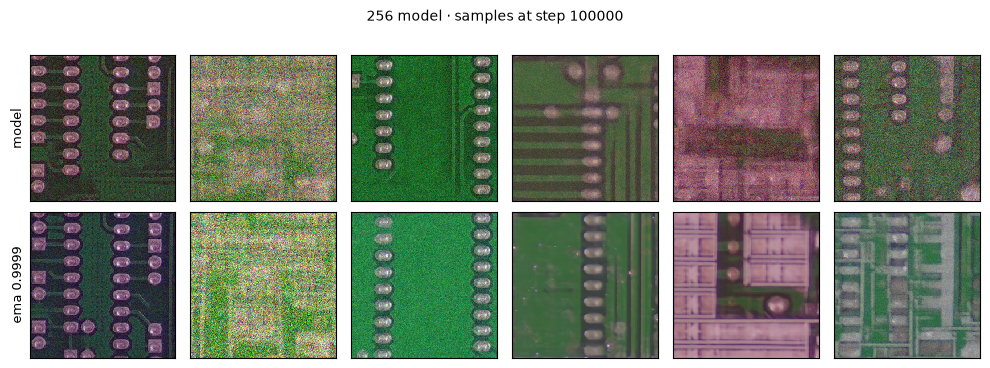

step 100500 · mse 0.0038 · vb 0.0024 · 17 img/s · 3072 min left


step 101000 · mse 0.0036 · vb 0.0023 · 19 img/s · 2763 min left


step 101500 · mse 0.0039 · vb 0.0017 · 19 img/s · 2798 min left


step 102000 · mse 0.0037 · vb 0.0019 · 19 img/s · 2809 min left


step 102500 · mse 0.0037 · vb 0.0021 · 19 img/s · 2793 min left


step 103000 · mse 0.0045 · vb 0.0031 · 19 img/s · 2743 min left


... (90 outputs left out)

step 148500 · mse 0.0037 · vb 0.0025 · 20 img/s · 2351 min left


step 149000 · mse 0.0040 · vb 0.0025 · 20 img/s · 2347 min left


step 149500 · mse 0.0035 · vb 0.0022 · 20 img/s · 2341 min left


step 150000 · mse 0.0039 · vb 0.0030 · 20 img/s · 2346 min left


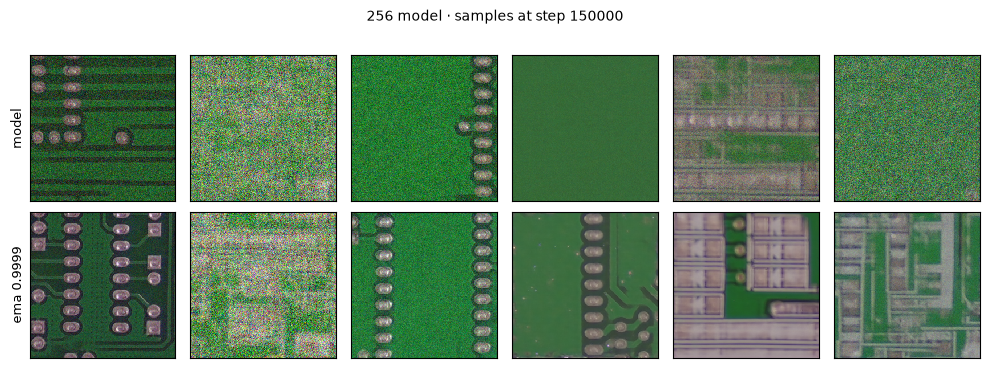

step 150500 · mse 0.0038 · vb 0.0021 · 18 img/s · 2570 min left


step 151000 · mse 0.0032 · vb 0.0020 · 20 img/s · 2339 min left


step 151500 · mse 0.0036 · vb 0.0015 · 20 img/s · 2328 min left


step 152000 · mse 0.0038 · vb 0.0022 · 20 img/s · 2324 min left


step 152500 · mse 0.0035 · vb 0.0019 · 20 img/s · 2331 min left


step 153000 · mse 0.0043 · vb 0.0025 · 20 img/s · 2318 min left


... (90 outputs left out)

step 198500 · mse 0.0034 · vb 0.0024 · 20 img/s · 2056 min left


step 199000 · mse 0.0038 · vb 0.0025 · 20 img/s · 2049 min left


step 199500 · mse 0.0035 · vb 0.0017 · 20 img/s · 2047 min left


step 200000 · mse 0.0033 · vb 0.0014 · 20 img/s · 2051 min left


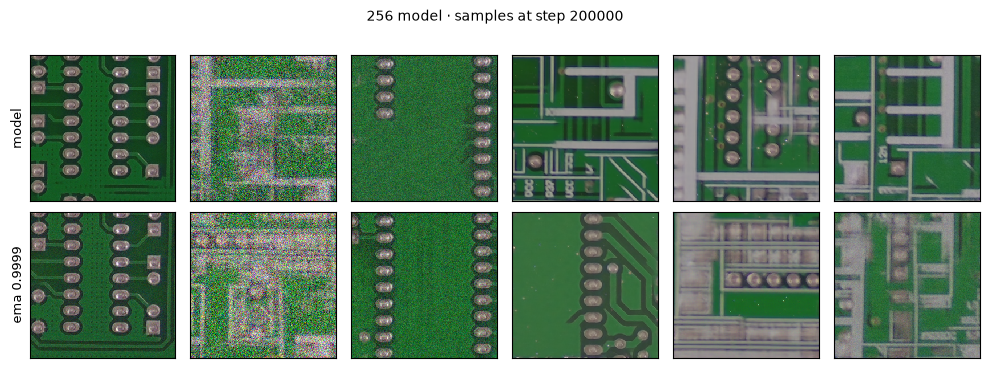

step 200500 · mse 0.0041 · vb 0.0025 · 18 img/s · 2247 min left


step 201000 · mse 0.0033 · vb 0.0019 · 20 img/s · 2037 min left


step 201500 · mse 0.0037 · vb 0.0017 · 20 img/s · 2029 min left


step 202000 · mse 0.0034 · vb 0.0010 · 19 img/s · 2038 min left


step 202500 · mse 0.0032 · vb 0.0016 · 20 img/s · 2021 min left


step 203000 · mse 0.0036 · vb 0.0033 · 20 img/s · 2030 min left


... (90 outputs left out)

step 248500 · mse 0.0031 · vb 0.0016 · 20 img/s · 1678 min left


step 249000 · mse 0.0033 · vb 0.0016 · 20 img/s · 1668 min left


step 249500 · mse 0.0037 · vb 0.0013 · 20 img/s · 1667 min left


step 250000 · mse 0.0036 · vb 0.0020 · 20 img/s · 1668 min left


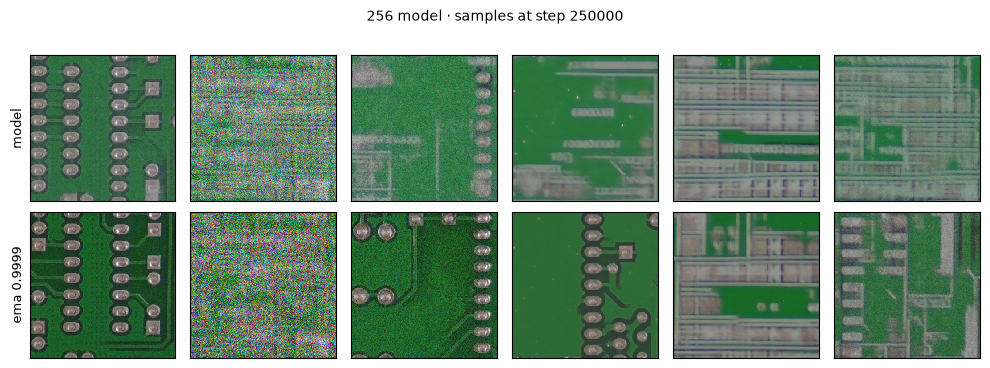

step 250500 · mse 0.0037 · vb 0.0019 · 18 img/s · 1827 min left


step 251000 · mse 0.0038 · vb 0.0039 · 20 img/s · 1656 min left


step 251500 · mse 0.0037 · vb 0.0026 · 20 img/s · 1658 min left


step 252000 · mse 0.0035 · vb 0.0027 · 20 img/s · 1652 min left


step 252500 · mse 0.0035 · vb 0.0024 · 20 img/s · 1647 min left


step 253000 · mse 0.0040 · vb 0.0023 · 20 img/s · 1641 min left


... (90 outputs left out)

step 298500 · mse 0.0028 · vb 0.0016 · 36 img/s · 746 min left


step 299000 · mse 0.0036 · vb 0.0021 · 36 img/s · 746 min left


step 299500 · mse 0.0031 · vb 0.0023 · 36 img/s · 744 min left


step 300000 · mse 0.0030 · vb 0.0016 · 36 img/s · 740 min left


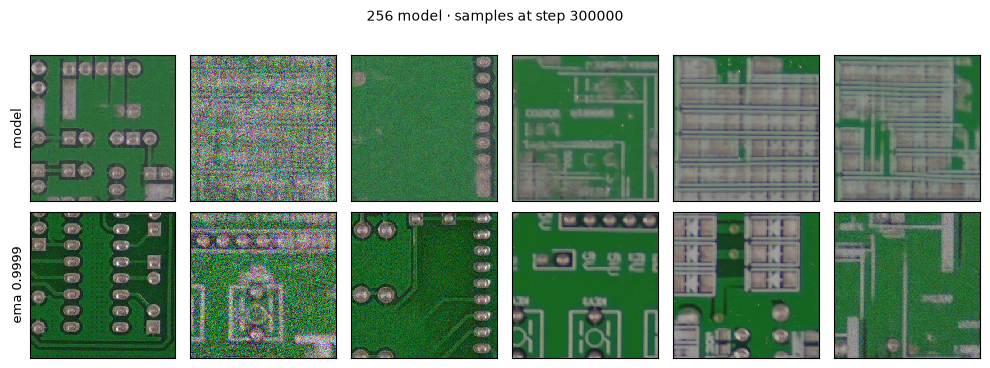

step 300500 · mse 0.0029 · vb 0.0025 · 32 img/s · 820 min left


step 301000 · mse 0.0030 · vb 0.0005 · 36 img/s · 738 min left


step 301500 · mse 0.0031 · vb 0.0016 · 36 img/s · 736 min left


step 302000 · mse 0.0030 · vb 0.0009 · 36 img/s · 732 min left


step 302500 · mse 0.0031 · vb 0.0020 · 36 img/s · 735 min left


step 303000 · mse 0.0037 · vb 0.0041 · 36 img/s · 729 min left


... (90 outputs left out)

step 348500 · mse 0.0032 · vb 0.0021 · 20 img/s · 1033 min left


step 349000 · mse 0.0038 · vb 0.0046 · 19 img/s · 1035 min left


step 349500 · mse 0.0032 · vb 0.0017 · 20 img/s · 1026 min left


step 350000 · mse 0.0037 · vb 0.0039 · 19 img/s · 1028 min left


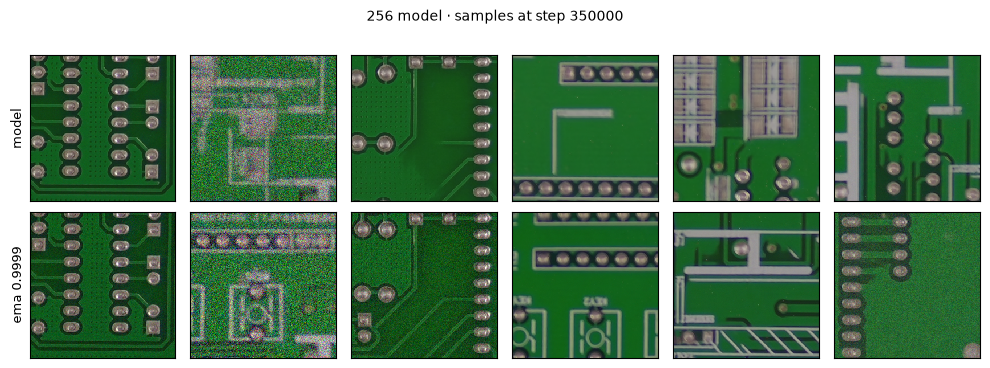

step 350500 · mse 0.0033 · vb 0.0023 · 18 img/s · 1119 min left


step 351000 · mse 0.0032 · vb 0.0014 · 20 img/s · 985 min left


step 351500 · mse 0.0031 · vb 0.0016 · 19 img/s · 1022 min left


step 352000 · mse 0.0032 · vb 0.0017 · 19 img/s · 1042 min left


step 352500 · mse 0.0031 · vb 0.0018 · 19 img/s · 1016 min left


step 353000 · mse 0.0036 · vb 0.0014 · 19 img/s · 1010 min left


... (90 outputs left out)

step 398500 · mse 0.0036 · vb 0.0040 · 20 img/s · 682 min left


step 399000 · mse 0.0031 · vb 0.0027 · 20 img/s · 678 min left


step 399500 · mse 0.0033 · vb 0.0019 · 20 img/s · 673 min left


step 400000 · mse 0.0026 · vb 0.0007 · 20 img/s · 672 min left


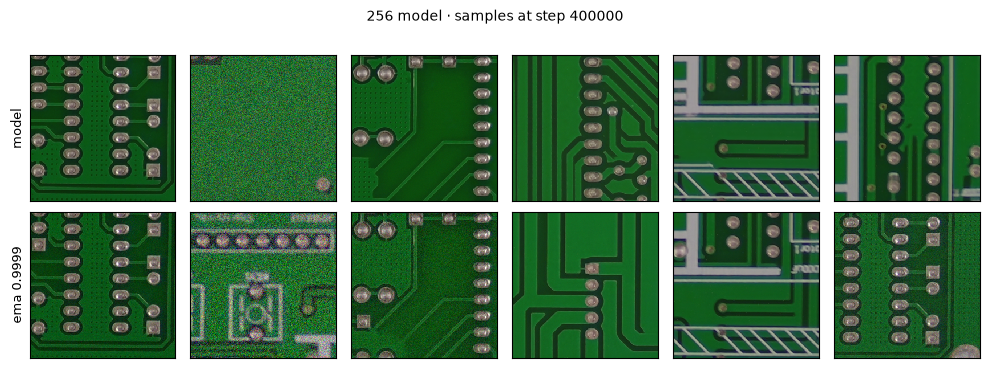

step 400500 · mse 0.0028 · vb 0.0008 · 18 img/s · 737 min left


step 401000 · mse 0.0033 · vb 0.0031 · 20 img/s · 665 min left


step 401500 · mse 0.0034 · vb 0.0027 · 20 img/s · 659 min left


step 402000 · mse 0.0029 · vb 0.0020 · 20 img/s · 643 min left


step 402500 · mse 0.0029 · vb 0.0013 · 20 img/s · 661 min left


step 403000 · mse 0.0028 · vb 0.0016 · 20 img/s · 659 min left


... (90 outputs left out)

step 448500 · mse 0.0035 · vb 0.0033 · 19 img/s · 355 min left


step 449000 · mse 0.0029 · vb 0.0023 · 19 img/s · 352 min left


step 449500 · mse 0.0033 · vb 0.0027 · 19 img/s · 349 min left


step 450000 · mse 0.0030 · vb 0.0016 · 19 img/s · 345 min left


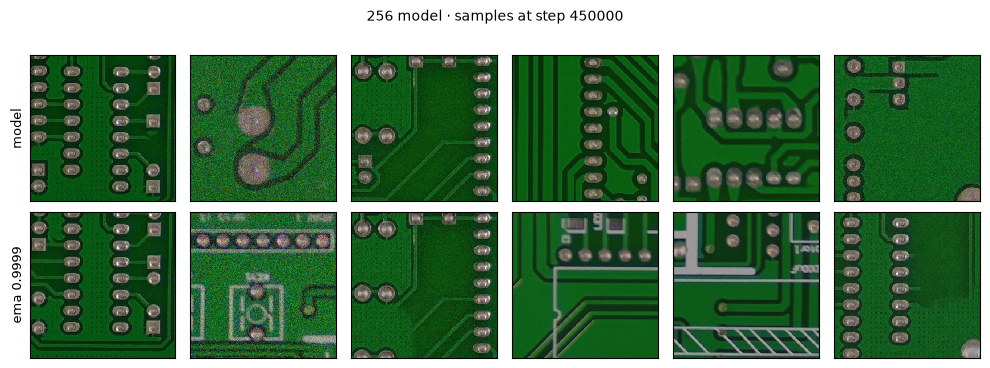

step 450500 · mse 0.0030 · vb 0.0011 · 18 img/s · 376 min left


step 451000 · mse 0.0030 · vb 0.0027 · 19 img/s · 338 min left


step 451500 · mse 0.0031 · vb 0.0021 · 19 img/s · 336 min left


step 452000 · mse 0.0033 · vb 0.0023 · 19 img/s · 330 min left


step 452500 · mse 0.0028 · vb 0.0013 · 19 img/s · 329 min left


step 453000 · mse 0.0032 · vb 0.0034 · 23 img/s · 270 min left


... (90 outputs left out)

step 498500 · mse 0.0036 · vb 0.0022 · 36 img/s · 6 min left


step 499000 · mse 0.0031 · vb 0.0008 · 36 img/s · 4 min left


step 499500 · mse 0.0026 · vb 0.0014 · 36 img/s · 2 min left


step 500000 · mse 0.0028 · vb 0.0015 · 36 img/s · 0 min left


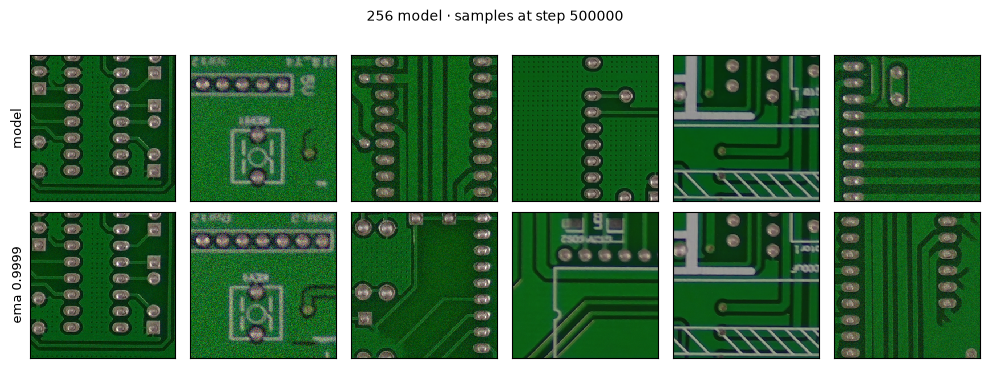

done: 256 model at step 500000 in 2730 min · /home/CNS2026014739/Projects/Diffusion_model/Graduate_Design/runs/free_256


In [8]:
# 释放步骤 1–4 演示用的模型和数据加载器
data.close()
del model
gc.collect(); torch.cuda.empty_cache()

for kind in ["64", "256"]:
    train(kind)

## Step 6 · Loss curves

The mse drops fast in the first few hundred steps and then slowly. Because every batch has different random timesteps the curve stays noisy, and a flat loss does **not** mean training is finished, nor that later is better: with only 300 defect patches the 64 model can start memorising them. Step 7 decides on held-out data instead.

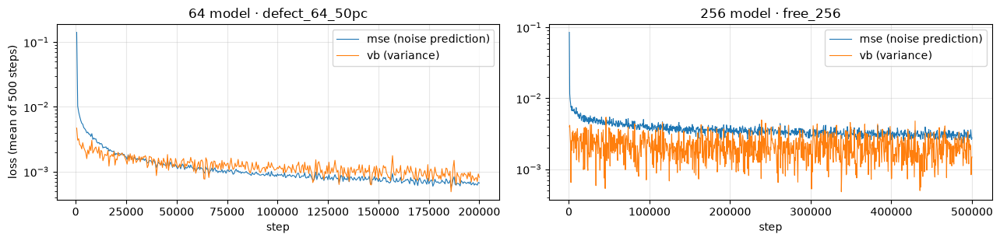

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for ax, kind in zip(axes, RUNS):
    h = json.load(open(run_dir(kind) / "loss_history.json"))
    ax.plot(h["step"], h["mse"], lw=0.8, label="mse (noise prediction)")
    ax.plot(h["step"], h["vb"], lw=0.8, label="vb (variance)")
    ax.set_yscale("log"), ax.set_xlabel("step"), ax.set_title(f"{kind} model · {run_dir(kind).name}")
    ax.legend(), ax.grid(alpha=0.3)
axes[0].set_ylabel(f"loss (mean of {LOG_EVERY} steps)")
plt.tight_layout(); plt.show()

## Step 7 · Held-out reference images and checkpoint selection

**Reference images.** Real images from the held-out **boards 10–12**, made the same way as the training data: photos shrunk to 0.5×, 64×64 patches around each labelled defect (same offset and rescaling rules), and 256×256 crops that do not touch any defect and stay 32 px from the photo edge.

The 152 held-out photos are split by index into two halves:

- **selection half**: used here to pick the best checkpoint of each of our runs
- **test half**: used only in Step 8, so the reported numbers are not tuned on the data they are measured on

**Selection metric.** KID between samples of each saved checkpoint and the selection half (lower is better). The training loss cannot show when the model starts to memorise its training images; this can.

Both weight sets are evaluated at every step, `model*.pt` and `ema_*.pt`. With EMA 0.9999 the averaged weights still contain $0.9999^{\,s}$ of the random initial weights after $s$ steps (37% at 10k, 5% at 30k, 0.7% at 50k), so early EMA checkpoints are poor even when the raw weights are already good. With only 300 defect patches the best moment may come before the EMA has settled; checking both finds it either way.

The earlier run on all 2,185 defect patches (`runs/defect_64/`, if present) is evaluated as well, as an extra entry.

In [10]:
import torch_fidelity

PKU = ROOT / "data" / "PKU-Market-PCB-corrected"
SCALE, PATCH, FREE = 0.5, 64, 256
MAX_OFFSET, RESCALE_FIT, FREE_MARGIN, EDGE_MARGIN = 8, 0.75, 8, 32
VAL = [Path(s).stem for s in (PKU / "ImageSets" / "val_board.txt").read_text().split()]
SELECT_STEMS, TEST_STEMS = VAL[0::2], VAL[1::2]


def real_sets(stems, free_per_photo=8, seed=SEED):
    """从留出板照片按训练数据同样的方式裁真实图像：(64 缺陷块, 类别, 256 无缺陷裁剪)，均为 uint8"""
    rng = random.Random(seed)
    d64, y64, f256 = [], [], []
    for s in stems:
        im = Image.open(PKU / "images" / f"{s}.jpg").convert("RGB")
        W, H = im.size
        im = im.resize((round(W * SCALE), round(H * SCALE)), Image.BICUBIC)
        w, h = im.size
        boxes = []
        for line in (PKU / "labels" / f"{s}.txt").read_text().splitlines():
            c, cx, cy, bw, bh = map(float, line.split())
            cx, cy, bw, bh = cx * w, cy * h, bw * w, bh * h
            boxes.append((int(c), cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2))
        for c, x0, y0, x1, y1 in boxes:                        # 与预处理相同：放不下就放大窗口再缩回 64
            bw, bh = x1 - x0, y1 - y0
            S = PATCH if max(bw, bh) <= PATCH else min(math.ceil(max(bw, bh) / RESCALE_FIT), w, h)
            off = MAX_OFFSET * S / PATCH
            cx = (x0 + x1) / 2 + rng.uniform(-max(0, min(off, (S - bw) / 2)), max(0, min(off, (S - bw) / 2)))
            cy = (y0 + y1) / 2 + rng.uniform(-max(0, min(off, (S - bh) / 2)), max(0, min(off, (S - bh) / 2)))
            l = int(round(min(max(cx - S / 2, 0), w - S))); t = int(round(min(max(cy - S / 2, 0), h - S)))
            p = im.crop((l, t, l + S, t + S))
            if S != PATCH:
                p = p.resize((PATCH, PATCH), Image.LANCZOS)
            d64.append(np.asarray(p)); y64.append(c)
        got = 0
        for _ in range(300):                                   # 256 无缺陷：随机窗口，碰到缺陷就丢弃
            if got == free_per_photo:
                break
            l = rng.randint(EDGE_MARGIN, w - FREE - EDGE_MARGIN); t = rng.randint(EDGE_MARGIN, h - FREE - EDGE_MARGIN)
            if any(x0 - FREE_MARGIN < l + FREE and x1 + FREE_MARGIN > l and y0 - FREE_MARGIN < t + FREE and
                   y1 + FREE_MARGIN > t for _, x0, y0, x1, y1 in boxes):
                continue
            f256.append(np.asarray(im.crop((l, t, l + FREE, t + FREE)))); got += 1
    to_t = lambda a: torch.from_numpy(np.stack(a)).permute(0, 3, 1, 2).contiguous()
    return to_t(d64), torch.tensor(y64), to_t(f256)


class U8(torch.utils.data.Dataset):
    """torch-fidelity 输入：uint8 (3,H,W) 图像"""
    def __init__(self, x): self.x = x
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.x[i]


def fidelity(gen, real, prc=True):
    n = min(len(gen), len(real))
    m = torch_fidelity.calculate_metrics(input1=U8(gen), input2=U8(real), cuda=True, fid=True, kid=True, prc=prc,
                                         kid_subset_size=min(1000, n), verbose=False)
    return m


def balanced_labels(n):
    return torch.arange(len(CLASSES)).repeat_interleave(n // len(CLASSES))


def load_ckpt(kind, path):
    net = build(kind).eval()
    net.load_state_dict(torch.load(path, map_location=device, weights_only=True))
    return net


sel_d64, sel_y64, sel_f256 = real_sets(SELECT_STEMS)
test_d64, test_y64, test_f256 = real_sets(TEST_STEMS)
REAL_SELECT = {"64": sel_d64, "256": sel_f256}
REAL_TEST = {"64": test_d64, "256": test_f256}
print(f"selection half: {len(SELECT_STEMS)} photos · {len(sel_d64)} defect patches · {len(sel_f256)} free crops")
print(f"test half:      {len(TEST_STEMS)} photos · {len(test_d64)} defect patches · {len(test_f256)} free crops")
print("test defect patches per class:", {ID2NAME[k]: v for k, v in sorted(Counter(test_y64.tolist()).items())})

selection half: 76 photos · 386 defect patches · 608 free crops
test half:      76 photos · 382 defect patches · 608 free crops
test defect patches per class: {'missinghole': 60, 'mousebite': 65, 'opencircuit': 66, 'short': 61, 'spur': 65, 'spuriouscopper': 65}


create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


ours · paper data (50/class) · ema_0.9999_002500.pt: KID×1e3 609.70 ± 1.23
create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


ours · paper data (50/class) · model002500.pt: KID×1e3 223.32 ± 2.28
create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


ours · paper data (50/class) · ema_0.9999_005000.pt: KID×1e3 631.07 ± 1.60
create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


ours · paper data (50/class) · model005000.pt: KID×1e3 136.27 ± 1.82
create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


ours · paper data (50/class) · ema_0.9999_007500.pt: KID×1e3 478.87 ± 2.31
create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


... (137 outputs left out)

ours · paper data (3,000 crops) · ema_0.9999_475000.pt: KID×1e3 90.70 ± 2.31
create model:image_size:256, attention_ds:[16, 32], use_fp16:False!


ours · paper data (3,000 crops) · model475000.pt: KID×1e3 140.64 ± 4.65
create model:image_size:256, attention_ds:[16, 32], use_fp16:False!


ours · paper data (3,000 crops) · ema_0.9999_500000.pt: KID×1e3 90.25 ± 2.41
create model:image_size:256, attention_ds:[16, 32], use_fp16:False!


ours · paper data (3,000 crops) · model500000.pt: KID×1e3 84.98 ± 2.84
→ best for ours · paper data (3,000 crops): model375000.pt (KID×1e3 40.90)


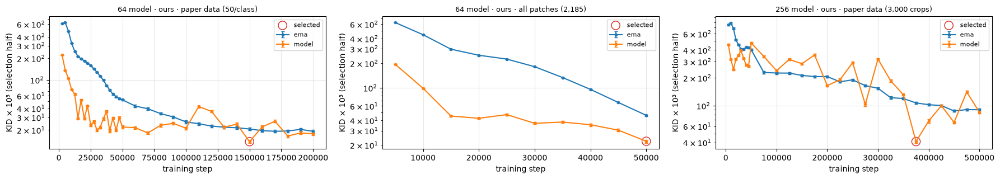

In [11]:
RESULTS.mkdir(parents=True, exist_ok=True)
SELECT_RUNS = {"64": {"ours · paper data (50/class)": run_dir("64")},
               "256": {"ours · paper data (3,000 crops)": run_dir("256")}}
if any((ROOT / "runs" / "defect_64").glob("model*.pt")):
    SELECT_RUNS["64"]["ours · all patches (2,185)"] = ROOT / "runs" / "defect_64"   # 先前用全部缺陷块训练的运行


def ckpt_step(p):
    return int(p.stem.split("_")[-1]) if p.stem.startswith("ema") else int(p.stem[5:])


selection, BEST = {}, {}
for kind, runs in SELECT_RUNS.items():
    for entry, d in runs.items():
        ckpts = sorted([*d.glob("model*.pt"), *d.glob("ema_*.pt")], key=lambda p: (ckpt_step(p), p.name))
        rows = []
        for ck in ckpts:
            net = load_ckpt(kind, ck)
            gen = ddim_sample(net, kind, y=balanced_labels(N_SELECT[kind]) if kind == "64" else None, n=N_SELECT[kind])
            m = fidelity(gen, REAL_SELECT[kind], prc=False)
            w = "ema" if ck.stem.startswith("ema") else "model"
            rows.append(dict(step=ckpt_step(ck), weights=w, file=ck.name, kid_x1e3=m["kernel_inception_distance_mean"] * 1e3,
                             kid_std_x1e3=m["kernel_inception_distance_std"] * 1e3, fid=m["frechet_inception_distance"]))
            print(f"{entry} · {ck.name}: KID×1e3 {rows[-1]['kid_x1e3']:.2f} ± {rows[-1]['kid_std_x1e3']:.2f}")
            del net; torch.cuda.empty_cache()
        selection[entry] = rows
        best = min(rows, key=lambda r: r["kid_x1e3"])
        BEST[entry] = (kind, d / best["file"])
        print(f"→ best for {entry}: {best['file']} (KID×1e3 {best['kid_x1e3']:.2f})")
json.dump({"selection": selection, "best": {k: str(v[1]) for k, v in BEST.items()}},
          open(RESULTS / "checkpoint_selection.json", "w"), indent=1)

fig, axes = plt.subplots(1, len(selection), figsize=(6 * len(selection), 3.3), squeeze=False)
for ax, (entry, rows) in zip(axes[0], selection.items()):
    df_s = pd.DataFrame(rows)
    for w, g in df_s.groupby("weights"):
        ax.errorbar(g["step"], g["kid_x1e3"], yerr=g["kid_std_x1e3"], marker="o", ms=3, capsize=2, label=w)
    best = min(rows, key=lambda r: r["kid_x1e3"])
    ax.scatter([best["step"]], [best["kid_x1e3"]], s=120, facecolors="none", edgecolors="tab:red", label="selected")
    ax.set_yscale("log"), ax.set_xlabel("training step"), ax.set_ylabel("KID × 10³ (selection half)")
    ax.set_title(f"{BEST[entry][0]} model · {entry}", fontsize=9), ax.grid(alpha=0.3), ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(RESULTS / "checkpoint_selection.png", dpi=110); plt.show()

## Step 8 · Benchmark: ours vs the authors' checkpoints

**Protocol.** Every model is sampled the same way (EMA weights, deterministic DDIM, 50 steps, same starting noise) and compared with the **test half** of the held-out boards. The models are evaluated on their own, without the CRG guidance, so this measures what each network has learned, not the paper's full generation pipeline.

| Metric | What it measures | Better |
|---|---|---|
| **KID × 10³** | distance between Inception-v3 feature distributions; unbiased, suited to small sets; the metric of the paper's Table IV | lower |
| FID | the same idea with a Gaussian fit; biased with a few hundred images, shown for reference | lower |
| Precision | share of generated images that fall inside the real-image manifold (fidelity) | higher |
| Recall | share of real images covered by the generated ones (diversity) | higher |
| NN ratio | median pixel distance of generated images to their nearest training-board image, divided by the same for real held-out images; well below 1 means near-copies of the training data | about 1 |

Computed with torch-fidelity 0.4.0 (Inception-v3 for FID/KID, VGG-16 for precision/recall). KID values depend on the library and the subset scheme, so compare them within this table, not with the numbers printed in the paper.

**Caveat on the authors' checkpoints.** Which boards they trained on is unknown. If boards 10–12 were included, their scores here are optimistic.

In [12]:
def nn_ratio(gen, real, pool):
    """生成图像到训练板图像池的最近邻像素距离中位数，除以真实留出图像的同一量"""
    P = pool.flatten(1).float().div(255).to(device)
    def med(a):
        d = [torch.cdist(a[i:i + 100].flatten(1).float().div(255).to(device), P).min(1).values
             for i in range(0, len(a), 100)]
        return torch.cat(d).median().item()
    r = med(gen) / med(real)
    del P; torch.cuda.empty_cache()
    return r


def load_pool(kind):
    d = ROOT / "data" / "pcb_processed" / ("defect_64" if kind == "64" else "free_256")
    return torch.stack([torch.from_numpy(np.array(Image.open(f).convert("RGB"))).permute(2, 0, 1)
                        for f in sorted(d.glob("*.jpg"))])


ENTRIES = {"64": {"authors": ROOT / "checkpoint" / "checkpoint-64-defect.pt"},
           "256": {"authors": ROOT / "checkpoint" / "checkpoint-256-defect-free.pt"}}
for entry, (kind, path) in BEST.items():                          # 每个自训运行在步骤 7 选出的 checkpoint
    ENTRIES[kind][entry] = path

table, per_class, SAMPLES = [], [], {}
for kind, entries in ENTRIES.items():
    pool = load_pool(kind)
    for name, path in entries.items():
        net = load_ckpt(kind, path)
        y = balanced_labels(N_TEST[kind]) if kind == "64" else None
        gen = ddim_sample(net, kind, y=y, n=N_TEST[kind], seed=SEED + 1)
        del net; torch.cuda.empty_cache()
        SAMPLES[(kind, name)] = gen
        m = fidelity(gen, REAL_TEST[kind])
        row = dict(model=kind, entry=name, checkpoint=Path(path).name,
                   kid_x1e3=m["kernel_inception_distance_mean"] * 1e3, kid_std_x1e3=m["kernel_inception_distance_std"] * 1e3,
                   fid=m["frechet_inception_distance"], precision=m["precision"], recall=m["recall"],
                   nn_ratio=nn_ratio(gen, REAL_TEST[kind], pool))
        table.append(row)
        print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()})
        if kind == "64":                                       # 每个缺陷类别的 KID（对应论文 Table IV 的形式）
            for cid, cname in ID2NAME.items():
                g, r = gen[y == cid], test_d64[test_y64 == cid]
                mm = torch_fidelity.calculate_metrics(input1=U8(g), input2=U8(r), cuda=True, kid=True, verbose=False,
                                                      kid_subset_size=min(len(g), len(r)))
                per_class.append(dict(entry=name, defect=cname, kid_x1e3=mm["kernel_inception_distance_mean"] * 1e3))
    del pool

df = pd.DataFrame(table)
df.to_csv(RESULTS / "benchmark.csv", index=False)
pc = pd.DataFrame(per_class).pivot(index="defect", columns="entry", values="kid_x1e3")
pc.loc["average"] = pc.mean()
pc.to_csv(RESULTS / "benchmark_per_class_kid.csv")
display(df.round(3))
display(pc.round(2))

create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


{'model': '64', 'entry': 'authors', 'checkpoint': 'checkpoint-64-defect.pt', 'kid_x1e3': 25.265, 'kid_std_x1e3': 0.897, 'fid': 84.289, 'precision': 0.262, 'recall': 0.505, 'nn_ratio': 0.972}


create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


{'model': '64', 'entry': 'ours · paper data (50/class)', 'checkpoint': 'model150000.pt', 'kid_x1e3': 11.973, 'kid_std_x1e3': 0.573, 'fid': 87.104, 'precision': 0.375, 'recall': 0.377, 'nn_ratio': 0.061}


create model:image_size:64, attention_ds:[4, 8], use_fp16:False!


{'model': '64', 'entry': 'ours · all patches (2,185)', 'checkpoint': 'model050000.pt', 'kid_x1e3': 21.002, 'kid_std_x1e3': 0.877, 'fid': 91.306, 'precision': 0.353, 'recall': 0.497, 'nn_ratio': 0.673}


create model:image_size:256, attention_ds:[16, 32], use_fp16:False!


{'model': '256', 'entry': 'authors', 'checkpoint': 'checkpoint-256-defect-free.pt', 'kid_x1e3': 97.988, 'kid_std_x1e3': 0.274, 'fid': 149.988, 'precision': 0.072, 'recall': 0.692, 'nn_ratio': 1.276}
create model:image_size:256, attention_ds:[16, 32], use_fp16:False!


{'model': '256', 'entry': 'ours · paper data (3,000 crops)', 'checkpoint': 'model375000.pt', 'kid_x1e3': 41.181, 'kid_std_x1e3': 0.186, 'fid': 114.468, 'precision': 0.025, 'recall': 0.199, 'nn_ratio': 1.069}


,model,entry,checkpoint,kid_x1e3,kid_std_x1e3,fid,precision,recall,nn_ratio
0,64,authors,checkpoint-64-defect.pt,25.265,0.897,84.289,0.262,0.505,0.972
1,64,ours · paper data (50/class),model150000.pt,11.973,0.573,87.104,0.375,0.377,0.061
2,64,"ours · all patches (2,185)",model050000.pt,21.002,0.877,91.306,0.353,0.497,0.673
3,256,authors,checkpoint-256-defect-free.pt,97.988,0.274,149.988,0.072,0.692,1.276
4,256,"ours · paper data (3,000 crops)",model375000.pt,41.181,0.186,114.468,0.025,0.199,1.069


entry,authors,"ours · all patches (2,185)",ours · paper data (50/class)
defect,,,
missinghole,25.98,45.05,37.68
mousebite,36.47,30.18,22.57
opencircuit,33.98,36.28,27.22
short,30.68,27.96,19.31
spur,33.66,30.12,18.76
spuriouscopper,36.96,32.45,24.97
average,32.95,33.67,25.08


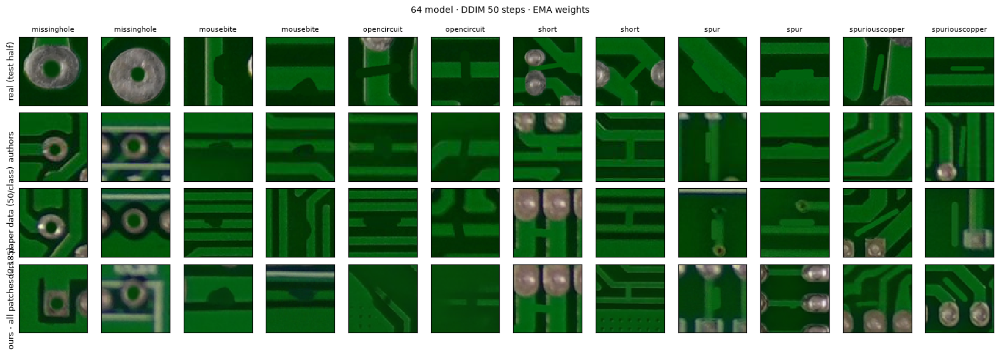

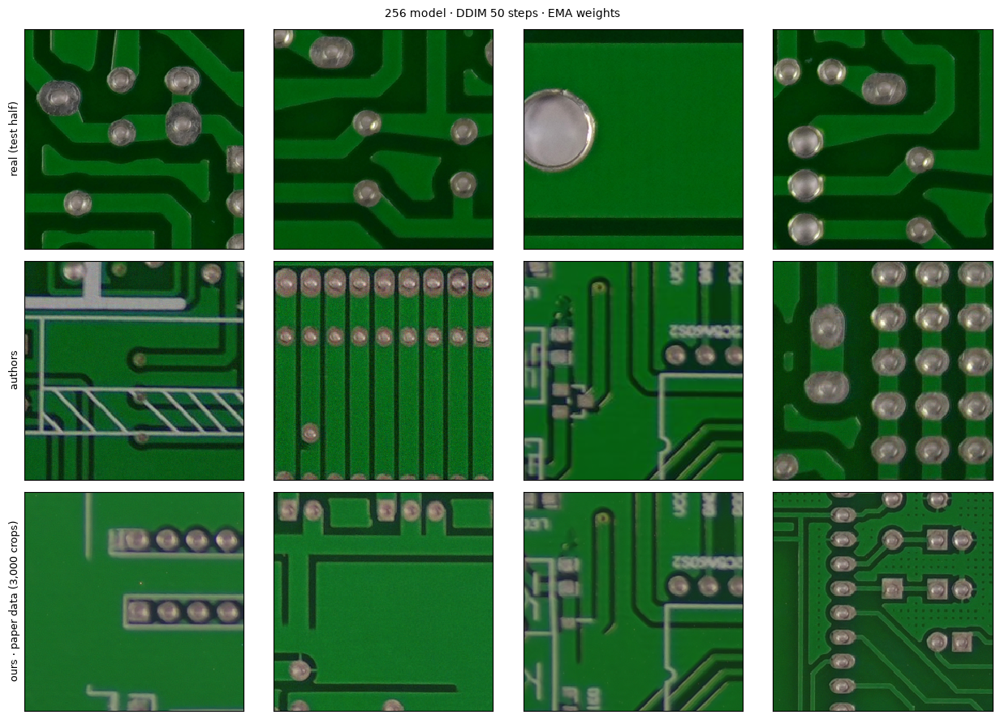

In [13]:
# 样本对比：同一份初始噪声，每行一个模型；最上面一行是真实的留出板图像
for kind, entries in ENTRIES.items():
    n_show = 12 if kind == "64" else 4
    if kind == "64":
        idx = torch.cat([torch.nonzero(balanced_labels(N_TEST[kind]) == c)[:2, 0] for c in range(len(CLASSES))])
        real_idx = torch.cat([torch.nonzero(test_y64 == c)[:2, 0] for c in range(len(CLASSES))])
        labels = [ID2NAME[c] for c in range(len(CLASSES)) for _ in range(2)]
    else:
        idx = torch.arange(n_show); real_idx = torch.arange(n_show); labels = None
    rows = [("real (test half)", REAL_TEST[kind][real_idx])] + [(name, SAMPLES[(kind, name)][idx]) for name in entries]
    cell = 1.2 if kind == "64" else 2.8
    fig, axes = plt.subplots(len(rows), n_show, figsize=(cell * n_show + 1.5, cell * len(rows) + 0.6), squeeze=False)
    for r, (name, imgs) in enumerate(rows):
        show_row(axes[r], imgs, labels if r == 0 else None, name)
    fig.suptitle(f"{kind} model · DDIM {EVAL_STEPS} steps · EMA weights", fontsize=10)
    plt.tight_layout(); fig.savefig(RESULTS / f"samples_{kind}.png", dpi=110); plt.show()

## How to read the results

- **KID / FID**: lower means the generated images are statistically closer to real held-out images. Differences smaller than the KID std are not meaningful.
- **Precision vs recall**: high precision with low recall means realistic but repetitive samples, a typical sign of memorisation with a small training set. High recall with low precision means varied but less realistic samples.
- **NN ratio**: about 1 means generated images are as far from the training images as unseen real images are. Well below 1 means the model reproduces training images.
- **Per-class KID**: shows which defect types each model handles worse. Each class has only about 50 real test patches, so these values are noisier than the overall ones.

All tables and figures are also saved in `results/comparison/`: `benchmark.csv`, `benchmark_per_class_kid.csv`, `checkpoint_selection.json/.png`, `samples_64.png`, `samples_256.png`.

**Next**: use the selected checkpoints in `confs/pcb_gen.yml` (`crop_model_path`, `model_path`) and run `sample_generation.py` to generate defects with the full CRG pipeline.